# Parados que llevan un año o más buscando empleo

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "paro-larga-duracion"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Parados que llevan un año o más buscando empleo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del total de parados"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de los parados que llevan doce meses o más buscando empleo (paro de larga duración), sobre el total de parados.

**Cómo se lee.** Un valor de 40 significa que cuatro de cada diez parados llevan un año o más en paro. Es un indicador de la composición del paro, no de su nivel: puede subir aunque baje el número de parados, si salen antes del paro quienes llevan menos tiempo.

**Limitaciones.**
- Al principio de una crisis entran muchos parados nuevos y el porcentaje baja; sube después, cuando esos parados acumulan meses.
- La duración es la que declara la persona encuestada en la encuesta de población activa.
- La tabla de Eurostat (`une_ltu_a`) empieza en 2009.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, paro por duración (`OECD.ELS.SAE,DSD_DUR@DF_DUR_I`, versión 1.0, *Incidence of unemployment by duration*): parados (`UNEMP`) con un año o más de duración (`Y_GE1`), en % del total de parados (`PT_POP_SUB`), ambos sexos, todas las edades, anual.
- **UE-27:** Eurostat `une_ltu_a`: paro de larga duración (`LTU`) en % de los parados (`PC_UNE`), de 15 a 74 años, ambos sexos.
- **Solo para las notas:** Eurostat `une_ltu_a` para España, para compararlo con la OCDE.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd

AREAS_OCDE = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
DATAFLOW_DUR = "OECD.ELS.SAE,DSD_DUR@DF_DUR_I,1.0"
# Dimensiones: país . medida . unidad . sexo . edad . duración . frecuencia
CLAVE_DUR = "{AREA}.UNEMP.PT_POP_SUB._T._T.Y_GE1.A"
FILTROS_EU = {"indic_em": "LTU", "age": "Y15-74", "sex": "T", "unit": "PC_UNE"}

oc, fuentes_oc = oecd.get(DATAFLOW_DUR, CLAVE_DUR, areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get("une_ltu_a", FILTROS_EU, geos={"EU27_2020": "ue27"}, desde=DESDE)
eu_esp, _ = eurostat.get("une_ltu_a", FILTROS_EU, geos={"ES": "espana"}, desde=DESDE)  # solo para las notas
print(oc.groupby("serie")["periodo"].agg(["min", "max"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max
serie             
canada  1976  2025
eeuu    1976  2025
espana  1986  2025
ocde    1983  2025
        min   max
serie            
ue27   2009  2025


## 3. Transformación

1. Las series se usan tal como las publican las fuentes. La OCDE no publica la UE-27 en este dataflow y se usa Eurostat.
2. **Comparación de España** en la OCDE (todas las edades) y en Eurostat (de 15 a 74 años), para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


df = pd.concat([oc, eu], ignore_index=True)
fuentes = [*fuentes_oc, *fuentes_eu]
assert df["valor"].between(0, 100).all(), "porcentaje fuera de rango"

NOTAS = [
    "España, EE. UU., Canadá y OCDE: OCDE, paro por duración (DSD_DUR@DF_DUR_I): parados que llevan un año o más "
    "buscando empleo, en % del total de parados, todas las edades, encuestas de población activa.",
    "UE-27: Eurostat (une_ltu_a), parados de 15 a 74 años con doce meses o más en paro, en % del total de parados, "
    "agregado de composición actual (EU27_2020).",
    nota_comparacion("Comparación de España en la OCDE y en Eurostat", serie(oc, "espana"), serie(eu_esp, "espana")),
    "El indicador mide la composición del paro, no su nivel: al principio de una crisis baja porque entran muchos "
    "parados nuevos.",
    "Rupturas de serie de la EPA: cambio de la definición de parado en 2001 y renovación de la encuesta en 2005.",
]
for n in NOTAS:
    print("-", n)

- España, EE. UU., Canadá y OCDE: OCDE, paro por duración (DSD_DUR@DF_DUR_I): parados que llevan un año o más buscando empleo, en % del total de parados, todas las edades, encuestas de población activa.
- UE-27: Eurostat (une_ltu_a), parados de 15 a 74 años con doce meses o más en paro, en % del total de parados, agregado de composición actual (EU27_2020).
- Comparación de España en la OCDE y en Eurostat: en los 17 años comunes (2009-2025), la diferencia máxima es de 0,05 puntos, en 2014.
- El indicador mide la composición del paro, no su nivel: al principio de una crisis baja porque entran muchos parados nuevos.
- Rupturas de serie de la EPA: cambio de la definición de parado en 2001 y renovación de la encuesta en 2005.


## 4. Visualización

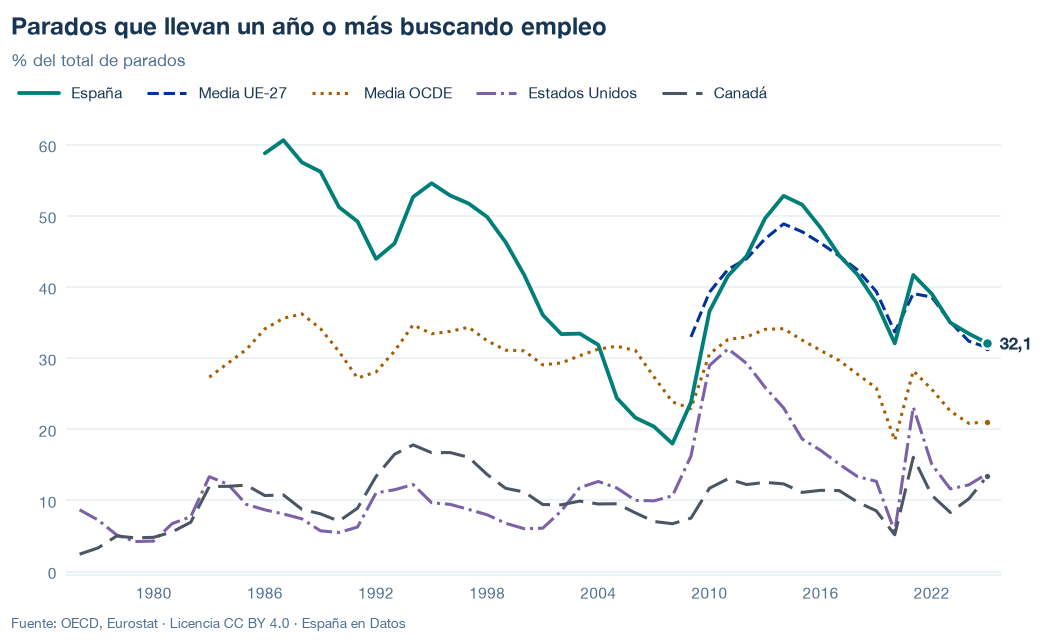

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/paro-larga-duracion.json y data/paro-larga-duracion.csv


## 6. Fuentes, notas y licencia

- OCDE, paro por duración: `OECD.ELS.SAE,DSD_DUR@DF_DUR_I,1.0` (`UNEMP`, `PT_POP_SUB`, `_T`, `_T`, `Y_GE1`, `A`). El config no fijaba el dataflow («a identificar en el Data Explorer»).
- Eurostat, `une_ltu_a` (`LTU`, `Y15-74`, `T`, `PC_UNE`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.